# Project 12: Understanding Convolution and Pooling
## Objective
To understand how convolution filters and pooling operations extract and summarize important visual features from an image.

## Introduction
Convolution applies a small filter, also called a kernel, across an image to highlight patterns such as edges and details. Pooling reduces the spatial size of a feature map while retaining prominent information. This project applies several filters and pooling techniques to a sample image and compares the results with the original.

## Task 1: Load a sample image using Python

A sample image is loaded from scikit-image and converted to grayscale so convolution can be demonstrated using a two-dimensional array.

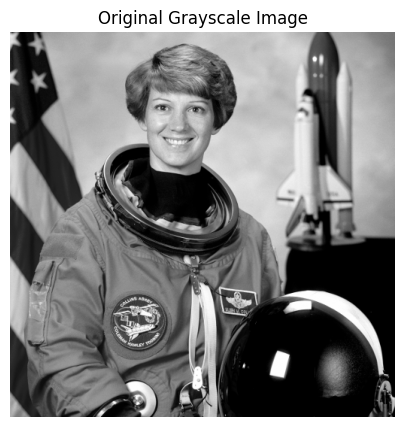

Image shape: (512, 512)


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, color, img_as_float
from scipy.ndimage import convolve

# Load and prepare a sample image
original_image = img_as_float(color.rgb2gray(data.astronaut()))

plt.figure(figsize=(6, 5))
plt.imshow(original_image, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")
plt.show()

print("Image shape:", original_image.shape)

## Task 2: Apply convolution filters and pooling operations

The experiment uses edge detection, sharpening, and blur filters. It also applies max pooling and average pooling to non-overlapping 2 × 2 regions.

In [2]:
# Define three convolution kernels
edge_kernel = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
], dtype=float)

sharpen_kernel = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
], dtype=float)

blur_kernel = np.ones((3, 3), dtype=float) / 9

# Apply each convolution filter
edge_map = convolve(original_image, edge_kernel, mode="reflect")
sharpened_image = convolve(original_image, sharpen_kernel, mode="reflect")
blurred_image = convolve(original_image, blur_kernel, mode="reflect")

# Prepare values for display
edge_display = np.clip(edge_map, 0, 1)
sharpen_display = np.clip(sharpened_image, 0, 1)
blur_display = np.clip(blurred_image, 0, 1)

# Create non-overlapping 2x2 regions for pooling
height = (original_image.shape[0] // 2) * 2
width = (original_image.shape[1] // 2) * 2
cropped = original_image[:height, :width]
regions = cropped.reshape(height // 2, 2, width // 2, 2)

max_pooled = regions.max(axis=(1, 3))
average_pooled = regions.mean(axis=(1, 3))

print("Original image size:", original_image.shape)
print("Max pooled size:", max_pooled.shape)
print("Average pooled size:", average_pooled.shape)

Original image size: (512, 512)
Max pooled size: (256, 256)
Average pooled size: (256, 256)


## Task 3: Visualize and compare the results

Edge detection highlights intensity changes, sharpening emphasizes details, and blur smooths fine details. Max pooling retains the largest value in each region, while average pooling uses the mean intensity.

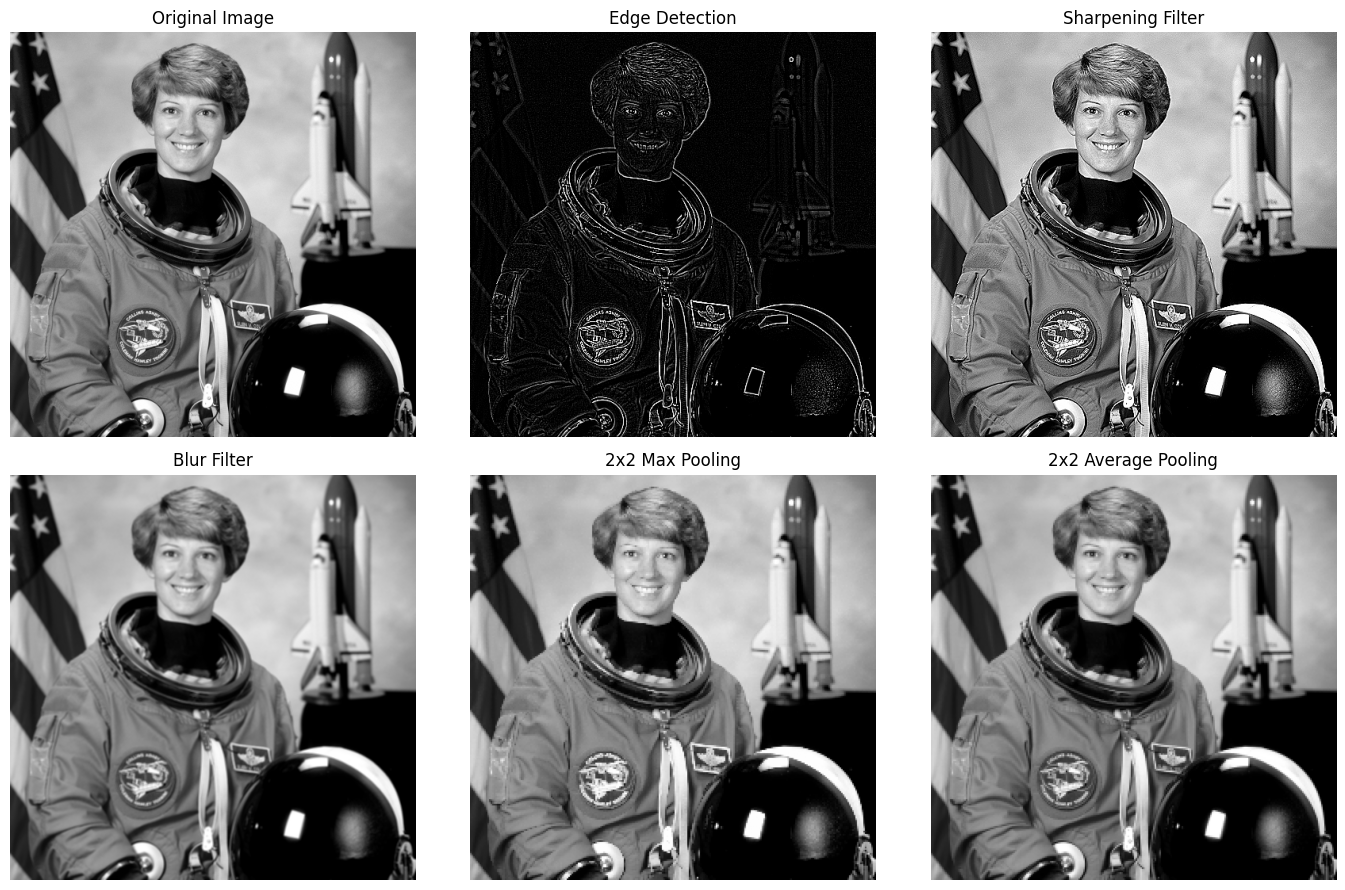

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(14, 9))

images = [
    (original_image, "Original Image"),
    (edge_display, "Edge Detection"),
    (sharpen_display, "Sharpening Filter"),
    (blur_display, "Blur Filter"),
    (max_pooled, "2x2 Max Pooling"),
    (average_pooled, "2x2 Average Pooling")
]

for ax, (image, title) in zip(axes.flat, images):
    ax.imshow(image, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [4]:
print(f"Original dimensions: {original_image.shape[0]} x {original_image.shape[1]}")
print(f"Max pooling dimensions: {max_pooled.shape[0]} x {max_pooled.shape[1]}")
print(f"Average pooling dimensions: {average_pooled.shape[0]} x {average_pooled.shape[1]}")

Original dimensions: 512 x 512
Max pooling dimensions: 256 x 256
Average pooling dimensions: 256 x 256


## Expected Output / Result

The original grayscale image and the processed images are displayed for comparison. Edge detection highlights boundaries and intensity changes, sharpening emphasizes details, and the blur filter smooths the image. Max pooling retains the strongest intensity in each 2 × 2 region, while average pooling calculates the mean intensity. Both pooling methods reduce the image's spatial dimensions, demonstrating how CNNs summarize visual information while reducing the amount of data processed.

## Conclusion

This project demonstrates how convolution filters reveal different image patterns and how pooling reduces feature-map size. These operations are important components of Convolutional Neural Networks because they help extract useful visual features and make image processing more efficient.